In [1]:
import mujoco
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

Matplotlib is building the font cache; this may take a moment.


In [2]:
model_path = Path("mujoco_menagerie/unitree_go2/scene.xml")

model = mujoco.MjModel.from_xml_path(str(model_path))
data = mujoco.MjData(model)

In [3]:
print("Bodies:", model.nbody)
print("Joints:", model.njnt)
print("Actuators:", model.nu)
print("Sensors:", model.nsensor)
print("Cameras:", model.ncam)
print("Simulation timestep:", model.opt.timestep)

Bodies: 14
Joints: 13
Actuators: 12
Sensors: 0
Cameras: 0
Simulation timestep: 0.002


In [4]:
def show_names(object_type, count):
    for i in range(count):
        name = mujoco.mj_id2name(model, object_type, i)
        print(f"{i}: {name}")

print("JOINTS")
show_names(mujoco.mjtObj.mjOBJ_JOINT, model.njnt)

print("\nACTUATORS")
show_names(mujoco.mjtObj.mjOBJ_ACTUATOR, model.nu)

print("\nSENSORS")
show_names(mujoco.mjtObj.mjOBJ_SENSOR, model.nsensor)

print("\nCAMERAS")
show_names(mujoco.mjtObj.mjOBJ_CAMERA, model.ncam)

JOINTS
0: None
1: FL_hip_joint
2: FL_thigh_joint
3: FL_calf_joint
4: FR_hip_joint
5: FR_thigh_joint
6: FR_calf_joint
7: RL_hip_joint
8: RL_thigh_joint
9: RL_calf_joint
10: RR_hip_joint
11: RR_thigh_joint
12: RR_calf_joint

ACTUATORS
0: FL_hip
1: FL_thigh
2: FL_calf
3: FR_hip
4: FR_thigh
5: FR_calf
6: RL_hip
7: RL_thigh
8: RL_calf
9: RR_hip
10: RR_thigh
11: RR_calf

SENSORS

CAMERAS


In [8]:
model.opt.gravity[:] = [0, 0, -9.81]

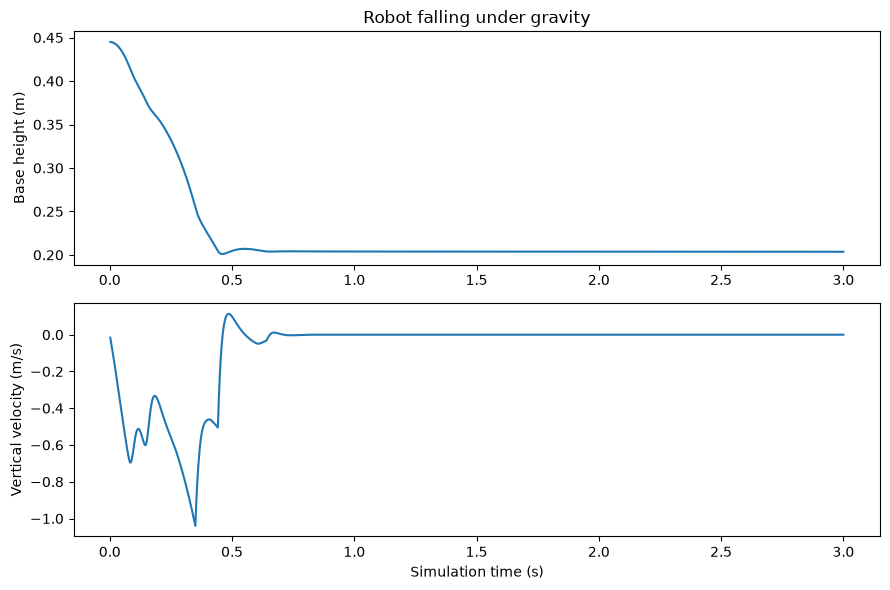

In [10]:
# Position and velocity over time
mujoco.mj_resetData(model, data)

times = []
heights = []
velocities = []

for _ in range(1500):
    mujoco.mj_step(model, data)

    times.append(data.time)
    heights.append(data.qpos[2])
    velocities.append(data.qvel[2])

fig, axes = plt.subplots(2, 1, figsize=(9, 6))

axes[0].plot(times, heights)
axes[0].set_ylabel("Base height (m)")
axes[0].set_title("Robot falling under gravity")

axes[1].plot(times, velocities)
axes[1].set_ylabel("Vertical velocity (m/s)")
axes[1].set_xlabel("Simulation time (s)")

plt.tight_layout()
plt.show()

In [11]:
# Actuators
for i in range(model.nu):
    name = mujoco.mj_id2name(
        model, mujoco.mjtObj.mjOBJ_ACTUATOR, i
    )
    print(
        name,
        "Limited:", bool(model.actuator_ctrllimited[i]),
        "Range:", model.actuator_ctrlrange[i]
    )

FL_hip Limited: True Range: [-23.7  23.7]
FL_thigh Limited: True Range: [-23.7  23.7]
FL_calf Limited: True Range: [-45.43  45.43]
FR_hip Limited: True Range: [-23.7  23.7]
FR_thigh Limited: True Range: [-23.7  23.7]
FR_calf Limited: True Range: [-45.43  45.43]
RL_hip Limited: True Range: [-23.7  23.7]
RL_thigh Limited: True Range: [-23.7  23.7]
RL_calf Limited: True Range: [-45.43  45.43]
RR_hip Limited: True Range: [-23.7  23.7]
RR_thigh Limited: True Range: [-23.7  23.7]
RR_calf Limited: True Range: [-45.43  45.43]


In [12]:
mujoco.mj_resetData(model, data)

# Set each limited actuator to the midpoint of its range.
# Leave unlimited actuators at zero.
data.ctrl[:] = 0

for i in range(model.nu):
    if model.actuator_ctrllimited[i]:
        low, high = model.actuator_ctrlrange[i]
        data.ctrl[i] = (low + high) / 2

for _ in range(1000):
    mujoco.mj_step(model, data)

print("Final joint positions:")
print(data.qpos)

Final joint positions:
[-2.31660937e-01 -4.84094612e-04  2.03746891e-01  9.98428411e-01
  2.85017883e-03 -5.59487583e-02 -1.52356590e-03 -3.89825309e-02
 -1.40542248e-01 -1.31980094e+00  4.03546584e-02 -1.47405671e-01
 -1.31925265e+00 -2.37919173e-03 -5.26963755e-01 -1.27905869e+00
 -6.42413170e-03 -5.28663788e-01 -1.32097966e+00]


In [13]:
mujoco.mj_forward(model, data)

if model.nsensor == 0:
    print("This model has no predefined sensors.")
else:
    for i in range(model.nsensor):
        sensor = model.sensor(i)
        start = model.sensor_adr[i]
        size = model.sensor_dim[i]

        values = data.sensordata[start:start + size]

        print(f"{sensor.name}: {values}")

This model has no predefined sensors.


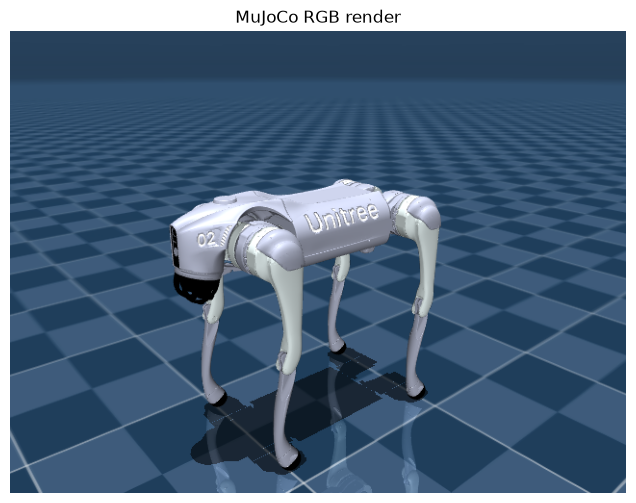

In [14]:
mujoco.mj_resetData(model, data)
mujoco.mj_forward(model, data)

renderer = mujoco.Renderer(model, height=480, width=640)

renderer.update_scene(data)
rgb_image = renderer.render().copy()

plt.figure(figsize=(10, 6))
plt.imshow(rgb_image)
plt.axis("off")
plt.title("MuJoCo RGB render")
plt.show()

renderer.close()